In [93]:
"""
    Principal Component Analysis (PCA) from scratch.
    
    The mathematical model in this notebook is derived from the Mathematics for Machine Learning book by Marc Peter Deisenroth, A. Aldo Faisal, and Cheng Soon Ong.
    Specifically chapter 10, which is dedicated to PCA. The book is available for free online at https://mml-book.github.io/book/mml-book.pdf.

    NOTE: this part for the data is AI Generated 
"""
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

N = 200
theta_true = np.deg2rad(30)          # ground truth: the direction PCA should find

# 1. stretched cloud, axis-aligned: wide in x, thin in y
X = rng.normal(0, 1, size=(N, 2)) * np.array([3.0, 0.6])

# 2. rotate it
R = np.array([[np.cos(theta_true), -np.sin(theta_true)],
              [np.sin(theta_true),  np.cos(theta_true)]])
X = X @ R.T


# 3. shove it off-origin, so you have to center it yourself
X += np.array([4.0, -2.0])

In [94]:
"""
    Sanity check for data
"""
X[:5]

array([[ 5.10367343, -2.08331597],
       [ 5.66755998, -0.38559144],
       [-0.67828426, -5.6031851 ],
       [ 4.42701189, -1.97256387],
       [ 4.21226249, -2.46845636]])

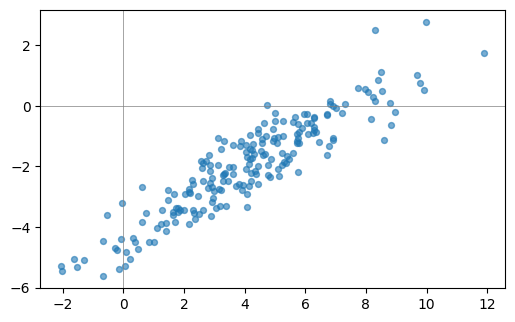

In [95]:
plt.figure(figsize=(6, 6))
plt.scatter(X[:, 0], X[:, 1], s=18, alpha=0.6)
plt.axhline(0, lw=0.5, c='gray'); plt.axvline(0, lw=0.5, c='gray')
plt.gca().set_aspect('equal')
plt.show()

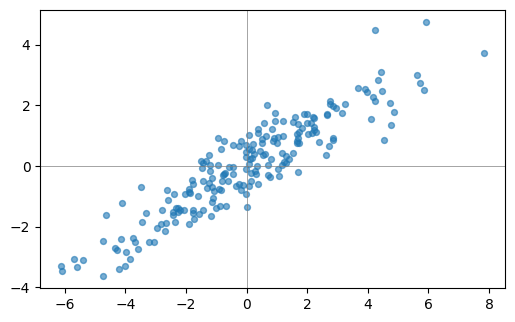

In [96]:
"""
    Standardization step for the data:
    
    PCA is sensitive to the scale and size difference between the features of the data, 
    so we need to standardize it before applying PCA. 
    This involves centering the data by subtracting the mean and scaling it by
    dividing by the standard deviation.
    
    NOTE: We ONLY subtract the mean here — we do NOT divide by std.
    Dividing by std (full standardization) equalizes the spread across all axes,
    which destroys the variance differences that PCA is trying to find.
    Full standardization is useful when features have different units
    (e.g. height in cm vs salary in dollars), but for same-unit data
    it collapses the shape of the cloud into a circle and PCA finds nothing.
    
"""

def standardize(X):
    """
        Standardizes the data by centering and scaling.
        
        Parameters:
            X (numpy.ndarray): The input data to be standardized.
        
        Returns:
            numpy.ndarray: The standardized data.
    """
    mean = np.mean(X, axis=0)
    # std = np.std(X, axis=0)
    return X - mean


standardized_X = standardize(X)

plt.figure(figsize=(6, 6))
plt.scatter(standardized_X[:, 0], standardized_X[:, 1], s=18, alpha=0.6)
plt.axhline(0, lw=0.5, c='gray'); plt.axvline(0, lw=0.5, c='gray')
plt.gca().set_aspect('equal')
plt.show()

In [97]:
"""
    After standardization, we can compute the covariance matrix of the standardized data.
    
    The reason for computing the covariance matrix is to understand how the features of the data vary with respect to each other.
    And the covariance matrix is a key component in PCA, 
    as it helps us identify the directions (principal components) along which the data varies the most.
    
    The covariance matrix is a square matrix that contains the covariances between pairs of features in the data.
    In simpler terms, it tells us how much two features change together. 
    A positive covariance indicates that the features tend to increase or decrease together, 
    while a negative covariance indicates that one feature tends to increase when the other decreases.
"""

def compute_covariance_matrix(X):
    """
        Computes the covariance matrix of the input data.
        
        Parameters:
            X (numpy.ndarray): The input data for which to compute the covariance matrix.
        
        Returns:
            numpy.ndarray: The covariance matrix of the input data.
    """
    n_samples = X.shape[0]
    return (X.T @ X) / (n_samples)

covariance_matrix = compute_covariance_matrix(standardized_X)

covariance_matrix

array([[6.55580145, 3.70952053],
       [3.70952053, 2.49902408]])

In [99]:
print(np.linalg.eigh(covariance_matrix))
print(theta_true)

EighResult(eigenvalues=array([0.29954057, 8.75528496]), eigenvectors=array([[ 0.51001674, -0.86016448],
       [-0.86016448, -0.51001674]]))
0.5235987755982988
